In [47]:
# Load Data and Define X, y

from pathlib import Path
import pandas as pd

base_dir = Path("/content/drive/My Drive/gdsc-drug-response")
data_path = base_dir / "processed" / "gdsc_fulvestrant_ln_ic50_modelready.csv"

df = pd.read_csv(data_path)

response_col = "LN_IC50"
drug_col     = "DRUG_NAME"
cell_col     = "CELL_LINE_NAME"
non_feature_cols = [drug_col, cell_col, response_col]


non_numeric_cols = df.select_dtypes(exclude=["number"]).columns.tolist()
numeric_cols     = df.select_dtypes(include=["number"]).columns.tolist()

non_numeric_cols, numeric_cols[:10]

# Take all numeric columns, then remove the target
#numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
#leak_cols = ["Z_SCORE", "AUC"]
#feature_cols = [c for c in feature_cols if c not in leak_cols and c != response_col]
#feature_cols = [c for c in df.columns if c not in non_feature_cols]

#X = df[feature_cols].values
#y = df[response_col].values
#X.shape, y.shape

(['DRUG_NAME',
  'CELL_LINE_NAME',
  'Cancer Type (matching TCGA label)',
  'Microsatellite instability Status (MSI)',
  'GDSC Tissue descriptor 2',
  'GDSC Tissue descriptor 1',
  'CNA',
  'Growth Properties',
  'Screen Medium',
  'Gene Expression',
  'Methylation',
  'TCGA_DESC',
  'TARGET',
  'TARGET_PATHWAY'],
 ['LN_IC50', 'DRUG_ID', 'AUC', 'Z_SCORE', 'COSMIC_ID'])

In [43]:
# Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
X_train.shape, X_test.shape

((1344, 16), (336, 16))

In [44]:
# Scale Features and Fit Ridge

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)   # you can tune alpha later
)

ridge.fit(X_train, y_train)

ValueError: could not convert string to float: 'ESCA'

In [39]:
# Evaluate on Train and Test

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_train_pred = ridge.predict(X_train)
y_test_pred  = ridge.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test  = r2_score(y_test, y_test_pred)

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test  = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train, r2_test, rmse_train, rmse_test

(0.3685866707116716,
 0.3759167776536506,
 np.float64(1.0078005063235134),
 np.float64(0.9698123484687391))

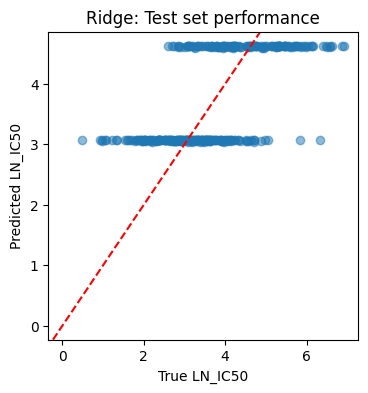

In [40]:
import matplotlib.pyplot as plt
plt.figure(figsize=(4,4))
plt.scatter(y_test, y_test_pred, alpha=0.5)
plt.xlabel("True LN_IC50")
plt.ylabel("Predicted LN_IC50")
plt.axline((0,0), slope=1, color="red", linestyle="--")
plt.title("Ridge: Test set performance")
plt.show()

In [41]:
print(feature_cols)

['DRUG_ID', 'COSMIC_ID']
